# Feature scaling

Age is in tens and salary is in tens of thousands. Models that measure **distance**, like K-NN, let the bigger numbers win. This notebook shows the problem and the fix: `StandardScaler`.

This notebook goes with the **Feature scaling** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

## 1. Load the data

`customers.csv` is a small made-up table of 80 shoppers: their **country**, **age** and **salary**, and whether they **purchased** (1) or not (0). It was generated for this course, so it is free to use. A few ages and salaries are left blank on purpose.

In [1]:
import numpy as np
import pandas as pd

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/customers.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,country,age,salary,purchased
0,Spain,37.0,49000.0,0
1,France,49.0,52000.0,1
2,France,37.0,35000.0,0
3,Germany,33.0,56500.0,1
4,Germany,24.0,29500.0,0


## 2. Split

We drop the rows with blanks, then hold out a test set. The scaler must only learn from the **training** rows.

In [2]:
from sklearn.model_selection import train_test_split

data = dataset.dropna()
X = data[['age', 'salary']].values
y = data['purchased'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

print('Spread (standard deviation) of each column in the training set:')
print('age   ', X_train[:, 0].std().round(1))
print('salary', X_train[:, 1].std().round(1))

Spread (standard deviation) of each column in the training set:
age    10.7
salary 16905.0


## 3. K-NN without scaling

Salary's spread is about a thousand times bigger than age's, so it decides almost every distance. Age hardly counts.

In [3]:
from sklearn.neighbors import KNeighborsClassifier

raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print('Test accuracy without scaling:', round(raw.score(X_test, y_test), 3))

Test accuracy without scaling: 0.647


## 4. Scale the features

`StandardScaler` subtracts each column's mean and divides by its standard deviation. `fit_transform` learns those two numbers from the training rows and applies them. `transform` reuses the **same** numbers on the test rows.

In [4]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

print('Training columns now have mean', X_train_s.mean(axis=0).round(2), 'and spread', X_train_s.std(axis=0).round(2))

Training columns now have mean [-0. -0.] and spread [1. 1.]


## 5. K-NN with scaling

Now age and salary both count when we measure distance.

In [5]:
scaled = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
print('Test accuracy with scaling:   ', round(scaled.score(X_test_s, y_test), 3))
print('Test accuracy without scaling:', round(raw.score(X_test, y_test), 3))

Test accuracy with scaling:    0.824
Test accuracy without scaling: 0.647


## 6. See who the nearest neighbour is

Pick one test person and ask for their single nearest training neighbour, in raw units and in scaled units. This is what the lesson's picture shows.

In [6]:
person = 0
raw_i = raw.kneighbors(X_test[[person]], n_neighbors=1, return_distance=False)[0][0]
scaled_i = scaled.kneighbors(X_test_s[[person]], n_neighbors=1, return_distance=False)[0][0]

print('Person:                ', X_test[person])
print('Nearest in raw units:  ', X_train[raw_i])
print('Nearest in scaled units:', X_train[scaled_i])

Person:                 [   49. 40000.]
Nearest in raw units:   [   44. 38500.]
Nearest in scaled units: [   51. 37000.]


## Try it yourself

- Change `person` to other numbers. How often is the nearest neighbour different?
- Replace `KNeighborsClassifier` with `DecisionTreeClassifier` and compare the scores with and without scaling. Why does a tree not care?

## See it: scaling changes who is "nearest"

Both panels show the same training shoppers and the same test shopper (black star). The line links the star to its **nearest training neighbour**. **Notice how** in raw units the nearest neighbour is chosen almost only by salary, because salary's numbers are about a thousand times bigger. After scaling, age counts as much as salary, and the nearest neighbour can change. The histograms underneath show what scaling did to each column: the shape stays, the numbers become small and centred on 0.

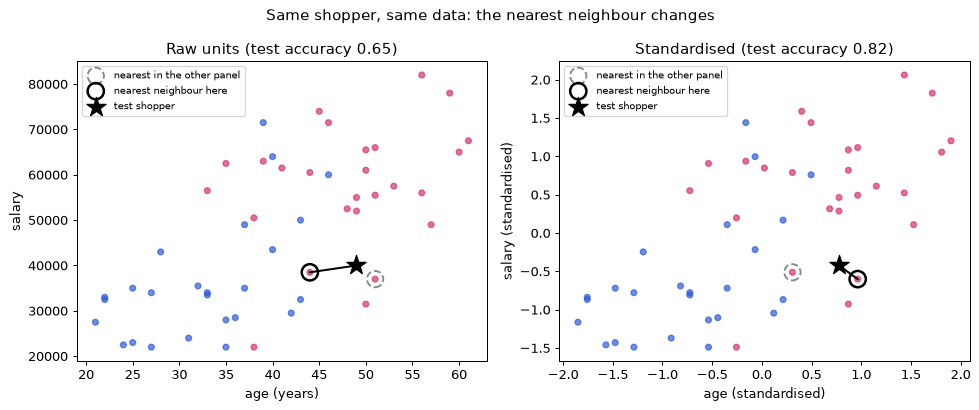

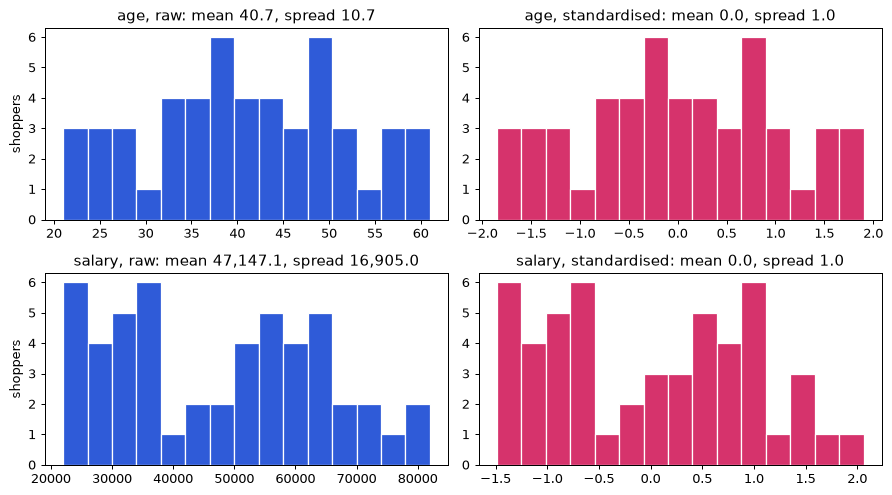

In [7]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

# Find a test shopper whose nearest neighbour is different in raw and in scaled units (fall back to person 0).
person = 0
for i in range(len(X_test)):
    a = raw.kneighbors(X_test[[i]], n_neighbors=1, return_distance=False)[0][0]
    b = scaled.kneighbors(X_test_s[[i]], n_neighbors=1, return_distance=False)[0][0]
    if a != b:
        person = i
        break
raw_i = raw.kneighbors(X_test[[person]], n_neighbors=1, return_distance=False)[0][0]
scaled_i = scaled.kneighbors(X_test_s[[person]], n_neighbors=1, return_distance=False)[0][0]

colors = np.array([BLUE, PINK])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, Xtr, Xte, nn, title, xl, yl in [
        (axes[0], X_train, X_test, raw_i, f'Raw units (test accuracy {raw.score(X_test, y_test):.2f})', 'age (years)', 'salary'),
        (axes[1], X_train_s, X_test_s, scaled_i, f'Standardised (test accuracy {scaled.score(X_test_s, y_test):.2f})', 'age (standardised)', 'salary (standardised)')]:
    ax.scatter(Xtr[:, 0], Xtr[:, 1], c=colors[y_train], s=22, alpha=0.7)
    ax.plot([Xte[person, 0], Xtr[nn, 0]], [Xte[person, 1], Xtr[nn, 1]], color='black', linewidth=1.6, zorder=3)
    other = scaled_i if nn == raw_i else raw_i
    if other != nn:
        ax.scatter(*Xtr[other], s=170, facecolors='none', edgecolors='#888888', linewidths=1.5, linestyle='--', zorder=4, label='nearest in the other panel')
    ax.scatter(*Xtr[nn], s=170, facecolors='none', edgecolors='black', linewidths=2, zorder=4, label='nearest neighbour here')
    ax.scatter(*Xte[person], marker='*', s=260, color='black', zorder=5, label='test shopper')
    ax.set_title(title)
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    ax.legend(loc='upper left', fontsize=8)
fig.suptitle('Same shopper, same data: the nearest neighbour ' + ('changes' if raw_i != scaled_i else 'is the same here (try another person)'))
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 5.6))
for r, (name, label) in enumerate([('age', 'age (years)'), ('salary', 'salary')]):
    axes[r, 0].hist(X_train[:, r], bins=15, color=BLUE, edgecolor='white')
    axes[r, 0].set_title(f'{name}, raw: mean {X_train[:, r].mean():,.1f}, spread {X_train[:, r].std():,.1f}')
    axes[r, 1].hist(X_train_s[:, r], bins=15, color=PINK, edgecolor='white')
    axes[r, 1].set_title(f'{name}, standardised: mean {X_train_s[:, r].mean().round(1) + 0.0:.1f}, spread {X_train_s[:, r].std():.1f}')
    axes[r, 0].set_ylabel('shoppers')
fig.tight_layout()
plt.show()
